# Phase 1 — ECG 1D CNN Golden-Float Notebook for Kaggle

This notebook implements **Phase 1: Algorithm Design & Optimization** for the 1D CNN ECG classifier.

It is intentionally packaged as a single Kaggle-ready `.ipynb` because the requested deliverable is only the notebook code.

Phase 1 output goals:
- Load and validate the MIT-BIH Arrhythmia CSV dataset.
- Train the PyTorch floating-point 1D CNN model.
- Save a quality baseline: accuracy, macro F1, confusion matrix, classification report, and predictions.
- Export all trained weights and biases.
- Export a bit-accurate FP32 golden reference set: inputs, labels, logits, probabilities, predictions, and intermediate layer activations.
- Generate Phase 1 markdown reports and package artifacts into a ZIP file.

Run the notebook top-to-bottom on Kaggle after attaching the MIT-BIH heartbeat dataset.

In [1]:
# ============================================================
# 0. Phase 1 configuration
# ============================================================
from __future__ import annotations

import csv
import gc
import json
import math
import os
import platform
import random
import shutil
import sys
import time
import zipfile
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from pathlib import Path
from typing import Dict, Iterable, List, Optional, Tuple

import numpy as np
import pandas as pd

# Kaggle usually has these installed already.
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset


@dataclass
class Phase1Config:
    """Configuration for the Kaggle Phase 1 golden-float run."""

    seed: int = 42

    # If None, the notebook searches under /kaggle/input for mitbih_train.csv.
    data_dir: Optional[str] = None

    output_root: str = "/kaggle/working/ecg_phase1_outputs"

    train_csv_name: str = "mitbih_train.csv"
    test_csv_name: str = "mitbih_test.csv"

    input_length: int = 187
    num_classes: int = 5

    val_fraction: float = 0.10
    batch_size: int = 128
    eval_batch_size: int = 512
    epochs: int = 30
    patience: int = 5
    learning_rate: float = 1e-3
    num_workers: int = 2

    # Keep False for bit-accurate FP32 golden reference.
    use_amp: bool = False

    # Keep False to match the hardware-friendly plan: no BatchNorm.
    use_batch_norm: bool = False

    # Optional fast debugging switches. Keep both as None for the final run.
    max_train_samples: Optional[int] = None
    max_test_samples: Optional[int] = None

    # Number of deterministic test samples exported as golden vectors.
    golden_sample_count: int = 128

    class_names: Tuple[str, ...] = (
        "N_Normal",
        "S_Supraventricular",
        "V_Ventricular",
        "F_Fusion",
        "Q_Unknown",
    )


CFG = Phase1Config()

# Make the notebook also runnable outside Kaggle for syntax/debug use.
if not Path("/kaggle/working").exists():
    CFG.output_root = "/mnt/data/ecg_phase1_outputs"

OUTPUT_ROOT = Path(CFG.output_root)
DIRS = {
    "root": OUTPUT_ROOT,
    "models": OUTPUT_ROOT / "models",
    "weights": OUTPUT_ROOT / "models" / "weights_float32",
    "golden": OUTPUT_ROOT / "datasets" / "golden_float",
    "reports": OUTPUT_ROOT / "docs" / "reports",
    "architecture": OUTPUT_ROOT / "docs" / "architecture",
    "figures": OUTPUT_ROOT / "docs" / "figures",
    "logs": OUTPUT_ROOT / "logs",
    "src": OUTPUT_ROOT / "models" / "float",
}

for directory in DIRS.values():
    directory.mkdir(parents=True, exist_ok=True)

print("Phase 1 output root:", OUTPUT_ROOT)
print("Notebook started at:", datetime.now(timezone.utc).isoformat())

Phase 1 output root: /kaggle/working/ecg_phase1_outputs
Notebook started at: 2026-06-06T00:06:14.760333+00:00


In [2]:
# ============================================================
# 1. Reproducibility and environment report
# ============================================================
def set_global_seed(seed: int) -> None:
    """Sets deterministic seeds for Python, NumPy, and PyTorch."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # Deterministic settings improve repeatability of exported golden vectors.
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


set_global_seed(CFG.seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = DEVICE.type == "cuda"

ENV_INFO = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version.replace("\n", " "),
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_device_count": torch.cuda.device_count(),
    "device": str(DEVICE),
}

if torch.cuda.is_available():
    ENV_INFO["cuda_device_name"] = torch.cuda.get_device_name(0)

with open(OUTPUT_ROOT / "environment.json", "w", encoding="utf-8") as f:
    json.dump(ENV_INFO, f, indent=2)

requirements_lines = [
    f"numpy=={np.__version__}",
    f"pandas=={pd.__version__}",
    "scikit-learn",
    "matplotlib",
    f"torch=={torch.__version__.split('+')[0]}",
]
(OUTPUT_ROOT / "requirements.txt").write_text("\n".join(requirements_lines) + "\n", encoding="utf-8")

print(json.dumps(ENV_INFO, indent=2))
print("\nWrote:", OUTPUT_ROOT / "requirements.txt")

{
  "timestamp_utc": "2026-06-06T00:06:15.027421+00:00",
  "python": "3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.35",
  "numpy": "2.0.2",
  "pandas": "2.3.3",
  "torch": "2.10.0+cu128",
  "cuda_available": true,
  "cuda_device_count": 2,
  "device": "cuda",
  "cuda_device_name": "Tesla T4"
}

Wrote: /kaggle/working/ecg_phase1_outputs/requirements.txt


In [3]:
# ============================================================
# 2. Locate and load MIT-BIH dataset
# ============================================================
def find_mitbih_data_dir(configured_dir: Optional[str]) -> Path:
    """Finds a directory containing MIT-BIH train/test CSV files.

    Args:
        configured_dir: Optional explicit dataset directory.

    Returns:
        Path to the dataset directory.

    Raises:
        FileNotFoundError: If the required CSV files cannot be found.
    """
    required = {CFG.train_csv_name, CFG.test_csv_name}

    candidate_dirs: List[Path] = []
    if configured_dir:
        candidate_dirs.append(Path(configured_dir))

    # Common Kaggle mount patterns.
    candidate_dirs.extend(
        [
            Path("/kaggle/input/heartbeat"),
            Path("/kaggle/input/ecg-heartbeat-categorization-dataset"),
            Path("/kaggle/input/datasets/shayanfazeli/heartbeat"),
            Path("/kaggle/input"),
        ]
    )

    for candidate in candidate_dirs:
        if candidate.exists():
            files = {p.name for p in candidate.glob("*.csv")}
            if required.issubset(files):
                return candidate

    # Recursive fallback search under Kaggle input.
    search_root = Path("/kaggle/input")
    if search_root.exists():
        train_matches = list(search_root.rglob(CFG.train_csv_name))
        for train_path in train_matches:
            candidate = train_path.parent
            if (candidate / CFG.test_csv_name).exists():
                return candidate

    raise FileNotFoundError(
        "Could not find MIT-BIH CSV files. Attach the Kaggle dataset that contains "
        f"{CFG.train_csv_name} and {CFG.test_csv_name}, or set CFG.data_dir explicitly."
    )


DATA_DIR = find_mitbih_data_dir(CFG.data_dir)
TRAIN_CSV = DATA_DIR / CFG.train_csv_name
TEST_CSV = DATA_DIR / CFG.test_csv_name

print("Found dataset directory:", DATA_DIR)
print("Train CSV:", TRAIN_CSV)
print("Test CSV:", TEST_CSV)

df_train_raw = pd.read_csv(TRAIN_CSV, header=None)
df_test_raw = pd.read_csv(TEST_CSV, header=None)

print("Raw train shape:", df_train_raw.shape)
print("Raw test shape:", df_test_raw.shape)
display(df_train_raw.head())

Found dataset directory: /kaggle/input/datasets/shayanfazeli/heartbeat
Train CSV: /kaggle/input/datasets/shayanfazeli/heartbeat/mitbih_train.csv
Test CSV: /kaggle/input/datasets/shayanfazeli/heartbeat/mitbih_test.csv
Raw train shape: (87554, 188)
Raw test shape: (21892, 188)


,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,0.977941,0.926471,0.681373,0.245098,0.154412,0.191176,0.151961,0.085784,0.058824,0.049020,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.960114,0.863248,0.461538,0.196581,0.094017,0.125356,0.099715,0.088319,0.074074,0.082621,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.000000,0.659459,0.186486,0.070270,0.070270,0.059459,0.056757,0.043243,0.054054,0.045946,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.925414,0.665746,0.541436,0.276243,0.196133,0.077348,0.071823,0.060773,0.066298,0.058011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.967136,1.000000,0.830986,0.586854,0.356808,0.248826,0.145540,0.089202,0.117371,0.150235,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
# ============================================================
# 3. Dataset validation and split
# ============================================================
def validate_mitbih_dataframe(df: pd.DataFrame, name: str) -> None:
    """Validates the MIT-BIH heartbeat CSV contract."""
    expected_cols = CFG.input_length + 1
    if df.shape[1] != expected_cols:
        raise ValueError(f"{name} must have {expected_cols} columns, got {df.shape[1]}.")

    labels = df[CFG.input_length].to_numpy()
    unique_labels = sorted(np.unique(labels).tolist())
    valid_labels = list(range(CFG.num_classes))
    if not set(unique_labels).issubset(valid_labels):
        raise ValueError(f"{name} has labels {unique_labels}, expected subset of {valid_labels}.")

    features = df.iloc[:, : CFG.input_length].to_numpy()
    if not np.isfinite(features).all():
        raise ValueError(f"{name} contains non-finite feature values.")


validate_mitbih_dataframe(df_train_raw, "train")
validate_mitbih_dataframe(df_test_raw, "test")

# Deterministic shuffle before split.
df_train = df_train_raw.sample(frac=1.0, random_state=CFG.seed).reset_index(drop=True)
df_test = df_test_raw.copy().reset_index(drop=True)

if CFG.max_train_samples is not None:
    # Stratified debug subset.
    df_train, _ = train_test_split(
        df_train,
        train_size=CFG.max_train_samples,
        random_state=CFG.seed,
        stratify=df_train[CFG.input_length],
    )
    df_train = df_train.reset_index(drop=True)

if CFG.max_test_samples is not None:
    df_test, _ = train_test_split(
        df_test,
        train_size=CFG.max_test_samples,
        random_state=CFG.seed,
        stratify=df_test[CFG.input_length],
    )
    df_test = df_test.reset_index(drop=True)

X_full = df_train.iloc[:, : CFG.input_length].to_numpy(dtype=np.float32)
y_full = df_train[CFG.input_length].to_numpy(dtype=np.int64)

X_test_np = df_test.iloc[:, : CFG.input_length].to_numpy(dtype=np.float32)
y_test_np = df_test[CFG.input_length].to_numpy(dtype=np.int64)

X_train_np, X_val_np, y_train_np, y_val_np = train_test_split(
    X_full,
    y_full,
    test_size=CFG.val_fraction,
    random_state=CFG.seed,
    stratify=y_full,
)

def class_distribution(labels: np.ndarray, split_name: str) -> pd.DataFrame:
    rows = []
    total = len(labels)
    for class_id, class_name in enumerate(CFG.class_names):
        count = int(np.sum(labels == class_id))
        rows.append(
            {
                "split": split_name,
                "class_id": class_id,
                "class_name": class_name,
                "count": count,
                "fraction": count / total if total else 0.0,
            }
        )
    return pd.DataFrame(rows)

dist_df = pd.concat(
    [
        class_distribution(y_train_np, "train"),
        class_distribution(y_val_np, "val"),
        class_distribution(y_test_np, "test"),
    ],
    ignore_index=True,
)
dist_df.to_csv(OUTPUT_ROOT / "dataset_class_distribution.csv", index=False)

data_contract = {
    "source_dir": str(DATA_DIR),
    "train_csv": str(TRAIN_CSV),
    "test_csv": str(TEST_CSV),
    "input_length": CFG.input_length,
    "feature_columns": list(range(CFG.input_length)),
    "label_column": CFG.input_length,
    "num_classes": CFG.num_classes,
    "class_names": list(CFG.class_names),
    "x_train_shape": list(X_train_np.shape),
    "x_val_shape": list(X_val_np.shape),
    "x_test_shape": list(X_test_np.shape),
    "dtype_features": str(X_train_np.dtype),
    "dtype_labels": str(y_train_np.dtype),
}
with open(OUTPUT_ROOT / "data_contract.json", "w", encoding="utf-8") as f:
    json.dump(data_contract, f, indent=2)

print("Train:", X_train_np.shape, y_train_np.shape)
print("Val:  ", X_val_np.shape, y_val_np.shape)
print("Test: ", X_test_np.shape, y_test_np.shape)
display(dist_df)

Train: (78798, 187) (78798,)
Val:   (8756, 187) (8756,)
Test:  (21892, 187) (21892,)


,split,class_id,class_name,count,fraction
0,train,0,N_Normal,65223,0.827724
1,train,1,S_Supraventricular,2001,0.025394
2,train,2,V_Ventricular,5209,0.066106
3,train,3,F_Fusion,577,0.007323
4,train,4,Q_Unknown,5788,0.073454
5,val,0,N_Normal,7248,0.827775
6,val,1,S_Supraventricular,222,0.025354
7,val,2,V_Ventricular,579,0.066126
8,val,3,F_Fusion,64,0.007309
9,val,4,Q_Unknown,643,0.073435


In [5]:
# ============================================================
# 4. PyTorch DataLoaders
# ============================================================
def make_tensor_dataset(features_np: np.ndarray, labels_np: np.ndarray) -> TensorDataset:
    """Converts ECG arrays to PyTorch Conv1d layout: (batch, channel, length)."""
    x = torch.tensor(features_np, dtype=torch.float32).unsqueeze(1)
    y = torch.tensor(labels_np, dtype=torch.long)
    return TensorDataset(x, y)


train_dataset = make_tensor_dataset(X_train_np, y_train_np)
val_dataset = make_tensor_dataset(X_val_np, y_val_np)
test_dataset = make_tensor_dataset(X_test_np, y_test_np)

train_loader = DataLoader(
    train_dataset,
    batch_size=CFG.batch_size,
    shuffle=True,
    num_workers=CFG.num_workers,
    pin_memory=PIN_MEMORY,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CFG.eval_batch_size,
    shuffle=False,
    num_workers=CFG.num_workers,
    pin_memory=PIN_MEMORY,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=CFG.eval_batch_size,
    shuffle=False,
    num_workers=CFG.num_workers,
    pin_memory=PIN_MEMORY,
)

print("DataLoaders ready.")
first_batch_x, first_batch_y = next(iter(train_loader))
print("Batch example:", first_batch_x.shape, first_batch_y.shape)

DataLoaders ready.
Batch example: torch.Size([128, 1, 187]) torch.Size([128])


In [6]:
# ============================================================
# 5. Hardware-friendly PyTorch 1D CNN model
# ============================================================
class ECG1DCNN(nn.Module):
    """1D CNN used as the Phase 1 FP32 golden reference.

    Input:
        x: Tensor with shape (B, 1, 187)

    Output:
        logits: Tensor with shape (B, 5)

    Notes:
        - Valid padding only.
        - BatchNorm disabled by default for hardware simplicity.
        - Dropout is active during training only and bypassed in eval mode.
    """

    def __init__(self, num_classes: int = 5, use_batch_norm: bool = False):
        super().__init__()
        self.use_batch_norm = use_batch_norm

        self.conv1 = nn.Conv1d(1, 16, kernel_size=5)
        self.bn1 = nn.BatchNorm1d(16) if use_batch_norm else nn.Identity()
        self.relu1 = nn.ReLU()

        self.conv2 = nn.Conv1d(16, 16, kernel_size=5)
        self.bn2 = nn.BatchNorm1d(16) if use_batch_norm else nn.Identity()
        self.relu2 = nn.ReLU()

        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)
        self.drop1 = nn.Dropout(0.1)

        self.conv3 = nn.Conv1d(16, 32, kernel_size=3)
        self.bn3 = nn.BatchNorm1d(32) if use_batch_norm else nn.Identity()
        self.relu3 = nn.ReLU()

        self.conv4 = nn.Conv1d(32, 32, kernel_size=3)
        self.bn4 = nn.BatchNorm1d(32) if use_batch_norm else nn.Identity()
        self.relu4 = nn.ReLU()

        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)
        self.drop2 = nn.Dropout(0.1)

        self.conv5 = nn.Conv1d(32, 256, kernel_size=3)
        self.bn5 = nn.BatchNorm1d(256) if use_batch_norm else nn.Identity()
        self.relu5 = nn.ReLU()

        self.conv6 = nn.Conv1d(256, 256, kernel_size=3)
        self.bn6 = nn.BatchNorm1d(256) if use_batch_norm else nn.Identity()
        self.relu6 = nn.ReLU()

        self.global_max_pool = nn.AdaptiveMaxPool1d(1)
        self.drop3 = nn.Dropout(0.2)

        self.fc1 = nn.Linear(256, 64)
        self.relu7 = nn.ReLU()

        self.fc2 = nn.Linear(64, 64)
        self.relu8 = nn.ReLU()

        self.fc3 = nn.Linear(64, num_classes)

    def forward_with_activations(self, x: torch.Tensor) -> Tuple[torch.Tensor, Dict[str, torch.Tensor]]:
        """Runs inference and returns intermediate activations for golden export."""
        activations: Dict[str, torch.Tensor] = {"input": x}

        x = self.conv1(x); activations["conv1"] = x
        x = self.bn1(x); activations["bn1_or_identity"] = x
        x = self.relu1(x); activations["relu1"] = x

        x = self.conv2(x); activations["conv2"] = x
        x = self.bn2(x); activations["bn2_or_identity"] = x
        x = self.relu2(x); activations["relu2"] = x

        x = self.pool1(x); activations["pool1"] = x
        x = self.drop1(x); activations["drop1_eval_identity"] = x

        x = self.conv3(x); activations["conv3"] = x
        x = self.bn3(x); activations["bn3_or_identity"] = x
        x = self.relu3(x); activations["relu3"] = x

        x = self.conv4(x); activations["conv4"] = x
        x = self.bn4(x); activations["bn4_or_identity"] = x
        x = self.relu4(x); activations["relu4"] = x

        x = self.pool2(x); activations["pool2"] = x
        x = self.drop2(x); activations["drop2_eval_identity"] = x

        x = self.conv5(x); activations["conv5"] = x
        x = self.bn5(x); activations["bn5_or_identity"] = x
        x = self.relu5(x); activations["relu5"] = x

        x = self.conv6(x); activations["conv6"] = x
        x = self.bn6(x); activations["bn6_or_identity"] = x
        x = self.relu6(x); activations["relu6"] = x

        x = self.global_max_pool(x); activations["global_max_pool"] = x
        x = self.drop3(x); activations["drop3_eval_identity"] = x

        x = torch.flatten(x, 1); activations["flatten"] = x

        x = self.fc1(x); activations["fc1"] = x
        x = self.relu7(x); activations["relu7"] = x

        x = self.fc2(x); activations["fc2"] = x
        x = self.relu8(x); activations["relu8"] = x

        logits = self.fc3(x); activations["logits"] = logits
        return logits, activations

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        logits, _ = self.forward_with_activations(x)
        return logits


model = ECG1DCNN(num_classes=CFG.num_classes, use_batch_norm=CFG.use_batch_norm).to(DEVICE)

param_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"Trainable parameters: {param_count:,}")

# Expected without BatchNorm: 248,693.
if not CFG.use_batch_norm:
    assert param_count == 248_693, f"Unexpected parameter count: {param_count}"

ECG1DCNN(
  (conv1): Conv1d(1, 16, kernel_size=(5,), stride=(1,))
  (bn1): Identity()
  (relu1): ReLU()
  (conv2): Conv1d(16, 16, kernel_size=(5,), stride=(1,))
  (bn2): Identity()
  (relu2): ReLU()
  (pool1): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (drop1): Dropout(p=0.1, inplace=False)
  (conv3): Conv1d(16, 32, kernel_size=(3,), stride=(1,))
  (bn3): Identity()
  (relu3): ReLU()
  (conv4): Conv1d(32, 32, kernel_size=(3,), stride=(1,))
  (bn4): Identity()
  (relu4): ReLU()
  (pool2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (drop2): Dropout(p=0.1, inplace=False)
  (conv5): Conv1d(32, 256, kernel_size=(3,), stride=(1,))
  (bn5): Identity()
  (relu5): ReLU()
  (conv6): Conv1d(256, 256, kernel_size=(3,), stride=(1,))
  (bn6): Identity()
  (relu6): ReLU()
  (global_max_pool): AdaptiveMaxPool1d(output_size=1)
  (drop3): Dropout(p=0.2, inplace=False)
  (fc1): Linear(in_features=256, out_features=64, bias=True)
  (relu7

In [7]:
# ============================================================
# 6. Shape trace and model architecture contract
# ============================================================
@torch.no_grad()
def export_shape_trace(model: nn.Module, output_csv: Path) -> pd.DataFrame:
    """Runs a dummy input through the model and saves all activation shapes."""
    model.eval()
    dummy = torch.zeros(2, 1, CFG.input_length, dtype=torch.float32, device=DEVICE)
    logits, activations = model.forward_with_activations(dummy)

    rows = []
    for name, tensor in activations.items():
        rows.append(
            {
                "activation_name": name,
                "shape": list(tensor.shape),
                "dtype": str(tensor.dtype).replace("torch.", ""),
            }
        )
    shape_df = pd.DataFrame(rows)
    shape_df.to_csv(output_csv, index=False)
    return shape_df


shape_df = export_shape_trace(model, OUTPUT_ROOT / "model_shape_trace.csv")
display(shape_df)

architecture_contract = {
    "model_name": "ECG1DCNN",
    "framework": "PyTorch",
    "input_shape": [None, 1, CFG.input_length],
    "output_shape": [None, CFG.num_classes],
    "padding": "valid",
    "batch_norm": CFG.use_batch_norm,
    "parameter_count": param_count,
    "activation_trace_csv": str(OUTPUT_ROOT / "model_shape_trace.csv"),
    "layers": shape_df.to_dict(orient="records"),
}
with open(DIRS["architecture"] / "model_architecture_contract_v01.json", "w", encoding="utf-8") as f:
    json.dump(architecture_contract, f, indent=2)

print("Saved architecture contract:", DIRS["architecture"] / "model_architecture_contract_v01.json")

,activation_name,shape,dtype
0,input,"[2, 1, 187]",float32
1,conv1,"[2, 16, 183]",float32
2,bn1_or_identity,"[2, 16, 183]",float32
3,relu1,"[2, 16, 183]",float32
4,conv2,"[2, 16, 179]",float32
5,bn2_or_identity,"[2, 16, 179]",float32
6,relu2,"[2, 16, 179]",float32
7,pool1,"[2, 16, 89]",float32
8,drop1_eval_identity,"[2, 16, 89]",float32
9,conv3,"[2, 32, 87]",float32


Saved architecture contract: /kaggle/working/ecg_phase1_outputs/docs/architecture/model_architecture_contract_v01.json


In [8]:
# ============================================================
# 7. Training and evaluation helper functions
# ============================================================
def run_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    optimizer: Optional[optim.Optimizer] = None,
) -> Dict[str, float]:
    """Runs one training or evaluation epoch."""
    is_train = optimizer is not None
    model.train(is_train)

    total_loss = 0.0
    total_count = 0
    correct = 0

    for inputs, labels in loader:
        inputs = inputs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_train):
            logits = model(inputs)
            loss = criterion(logits, labels)

            if is_train:
                loss.backward()
                optimizer.step()

        total_loss += float(loss.item()) * inputs.size(0)
        total_count += labels.size(0)
        correct += int((logits.argmax(dim=1) == labels).sum().item())

    return {
        "loss": total_loss / max(total_count, 1),
        "accuracy": correct / max(total_count, 1),
    }


@torch.no_grad()
def predict_logits(model: nn.Module, loader: DataLoader) -> Tuple[np.ndarray, np.ndarray]:
    """Returns logits and labels for a DataLoader."""
    model.eval()
    all_logits: List[np.ndarray] = []
    all_labels: List[np.ndarray] = []

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    for inputs, labels in loader:
        inputs = inputs.to(DEVICE, non_blocking=True)
        logits = model(inputs)
        all_logits.append(logits.detach().cpu().numpy().astype(np.float32))
        all_labels.append(labels.numpy().astype(np.int64))

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    return np.concatenate(all_logits, axis=0), np.concatenate(all_labels, axis=0)


def softmax_np(logits: np.ndarray) -> np.ndarray:
    """Numerically stable softmax for exported logits."""
    logits64 = logits.astype(np.float64)
    shifted = logits64 - logits64.max(axis=1, keepdims=True)
    exp = np.exp(shifted)
    probs = exp / exp.sum(axis=1, keepdims=True)
    return probs.astype(np.float32)

In [9]:
# ============================================================
# 8. Train the FP32 model with early stopping
# ============================================================
set_global_seed(CFG.seed)

model = ECG1DCNN(num_classes=CFG.num_classes, use_batch_norm=CFG.use_batch_norm).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=CFG.learning_rate)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.1,
    patience=3,
)

best_model_path = DIRS["models"] / "best_ecg1dcnn_float32.pth"
checkpoint_path = DIRS["models"] / "phase1_checkpoint.pth"
history_path = OUTPUT_ROOT / "training_history.csv"

history_rows: List[Dict[str, float]] = []
best_val_acc = -1.0
bad_epochs = 0
train_start = time.time()

for epoch in range(1, CFG.epochs + 1):
    train_metrics = run_one_epoch(model, train_loader, criterion, optimizer=optimizer)
    val_metrics = run_one_epoch(model, val_loader, criterion, optimizer=None)
    scheduler.step(val_metrics["accuracy"])

    row = {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "learning_rate": optimizer.param_groups[0]["lr"],
    }
    history_rows.append(row)

    print(
        f"Epoch {epoch:02d}/{CFG.epochs} | "
        f"train_loss={row['train_loss']:.5f} train_acc={row['train_accuracy']:.5f} | "
        f"val_loss={row['val_loss']:.5f} val_acc={row['val_accuracy']:.5f} | "
        f"lr={row['learning_rate']:.2e}"
    )

    if val_metrics["accuracy"] > best_val_acc:
        best_val_acc = val_metrics["accuracy"]
        bad_epochs = 0
        torch.save(model.state_dict(), best_model_path)
        print(f"  [SAVE] {best_model_path.name} val_acc={best_val_acc:.5f}")
    else:
        bad_epochs += 1

    pd.DataFrame(history_rows).to_csv(history_path, index=False)

    if bad_epochs >= CFG.patience:
        print(f"  [EARLY STOP] no validation improvement for {CFG.patience} epochs.")
        break

train_seconds = time.time() - train_start

# Save full checkpoint metadata.
torch.save(
    {
        "model_state_dict": torch.load(best_model_path, map_location="cpu"),
        "config": asdict(CFG),
        "best_val_accuracy": best_val_acc,
        "train_seconds": train_seconds,
        "history": history_rows,
        "param_count": param_count,
    },
    checkpoint_path,
)

print(f"\nTraining complete in {train_seconds:.2f} seconds.")
print("Best validation accuracy:", best_val_acc)
print("Saved:", best_model_path)
print("Saved:", checkpoint_path)
print("Saved:", history_path)

Epoch 01/30 | train_loss=0.53488 train_acc=0.82547 | val_loss=0.44163 val_acc=0.86341 | lr=1.00e-03
  [SAVE] best_ecg1dcnn_float32.pth val_acc=0.86341
Epoch 02/30 | train_loss=0.37976 train_acc=0.88016 | val_loss=0.29089 val_acc=0.91583 | lr=1.00e-03
  [SAVE] best_ecg1dcnn_float32.pth val_acc=0.91583
Epoch 03/30 | train_loss=0.27822 train_acc=0.91629 | val_loss=0.23527 val_acc=0.93011 | lr=1.00e-03
  [SAVE] best_ecg1dcnn_float32.pth val_acc=0.93011
Epoch 04/30 | train_loss=0.24011 train_acc=0.92950 | val_loss=0.21123 val_acc=0.94301 | lr=1.00e-03
  [SAVE] best_ecg1dcnn_float32.pth val_acc=0.94301
Epoch 05/30 | train_loss=0.21337 train_acc=0.93840 | val_loss=0.18779 val_acc=0.94861 | lr=1.00e-03
  [SAVE] best_ecg1dcnn_float32.pth val_acc=0.94861
Epoch 06/30 | train_loss=0.19200 train_acc=0.94520 | val_loss=0.16433 val_acc=0.95660 | lr=1.00e-03
  [SAVE] best_ecg1dcnn_float32.pth val_acc=0.95660
Epoch 07/30 | train_loss=0.17435 train_acc=0.95164 | val_loss=0.14890 val_acc=0.96174 | lr=1.0

In [10]:
# ============================================================
# 9. Test-set quality baseline
# ============================================================
model = ECG1DCNN(num_classes=CFG.num_classes, use_batch_norm=CFG.use_batch_norm).to(DEVICE)
model.load_state_dict(torch.load(best_model_path, map_location=DEVICE))
model.eval()

if torch.cuda.is_available():
    torch.cuda.synchronize()
inference_start = time.time()
test_logits, test_labels = predict_logits(model, test_loader)
if torch.cuda.is_available():
    torch.cuda.synchronize()
test_inference_seconds = time.time() - inference_start

test_probs = softmax_np(test_logits)
test_pred = test_probs.argmax(axis=1).astype(np.int64)

test_accuracy = accuracy_score(test_labels, test_pred)
test_macro_f1 = f1_score(test_labels, test_pred, average="macro")
cm = confusion_matrix(test_labels, test_pred, labels=list(range(CFG.num_classes)))
report_dict = classification_report(
    test_labels,
    test_pred,
    labels=list(range(CFG.num_classes)),
    target_names=list(CFG.class_names),
    output_dict=True,
    zero_division=0,
)
report_text = classification_report(
    test_labels,
    test_pred,
    labels=list(range(CFG.num_classes)),
    target_names=list(CFG.class_names),
    zero_division=0,
)

metrics = {
    "test_accuracy": float(test_accuracy),
    "test_macro_f1": float(test_macro_f1),
    "test_inference_seconds_full_set": float(test_inference_seconds),
    "test_samples": int(len(test_labels)),
    "average_inference_ms_per_sample": float(test_inference_seconds / max(len(test_labels), 1) * 1000.0),
    "best_val_accuracy": float(best_val_acc),
    "train_seconds": float(train_seconds),
    "parameter_count": int(param_count),
    "device": str(DEVICE),
}

with open(OUTPUT_ROOT / "quality_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

pd.DataFrame(report_dict).transpose().to_csv(OUTPUT_ROOT / "classification_report.csv")
pd.DataFrame(cm, index=CFG.class_names, columns=CFG.class_names).to_csv(OUTPUT_ROOT / "confusion_matrix.csv")

predictions_df = pd.DataFrame(
    {
        "sample_index": np.arange(len(test_labels)),
        "true_label": test_labels,
        "pred_label": test_pred,
        **{f"logit_{i}_{CFG.class_names[i]}": test_logits[:, i] for i in range(CFG.num_classes)},
        **{f"prob_{i}_{CFG.class_names[i]}": test_probs[:, i] for i in range(CFG.num_classes)},
    }
)
predictions_df.to_csv(OUTPUT_ROOT / "test_predictions_logits_probs.csv", index=False)

print("=== Test quality baseline ===")
print(json.dumps(metrics, indent=2))
print("\nClassification report:")
print(report_text)
print("Confusion matrix:")
print(cm)

=== Test quality baseline ===
{
  "test_accuracy": 0.9817284852914306,
  "test_macro_f1": 0.8904081739276324,
  "test_inference_seconds_full_set": 0.3380565643310547,
  "test_samples": 21892,
  "average_inference_ms_per_sample": 0.015442013718758208,
  "best_val_accuracy": 0.9837825491091823,
  "train_seconds": 147.882878780365,
  "parameter_count": 248693,
  "device": "cuda"
}

Classification report:
                    precision    recall  f1-score   support

          N_Normal       0.98      1.00      0.99     18118
S_Supraventricular       0.95      0.65      0.77       556
     V_Ventricular       0.95      0.96      0.95      1448
          F_Fusion       0.90      0.64      0.75       162
         Q_Unknown       0.99      0.99      0.99      1608

          accuracy                           0.98     21892
         macro avg       0.95      0.85      0.89     21892
      weighted avg       0.98      0.98      0.98     21892

Confusion matrix:
[[18053    17    33     6     9]
 

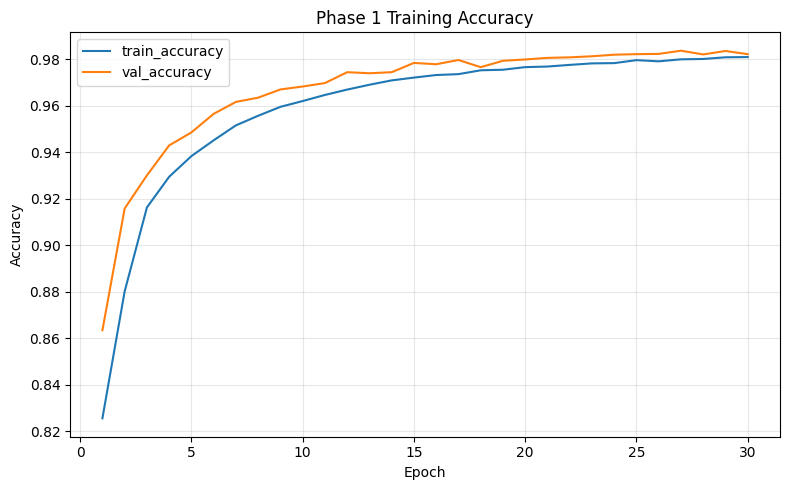

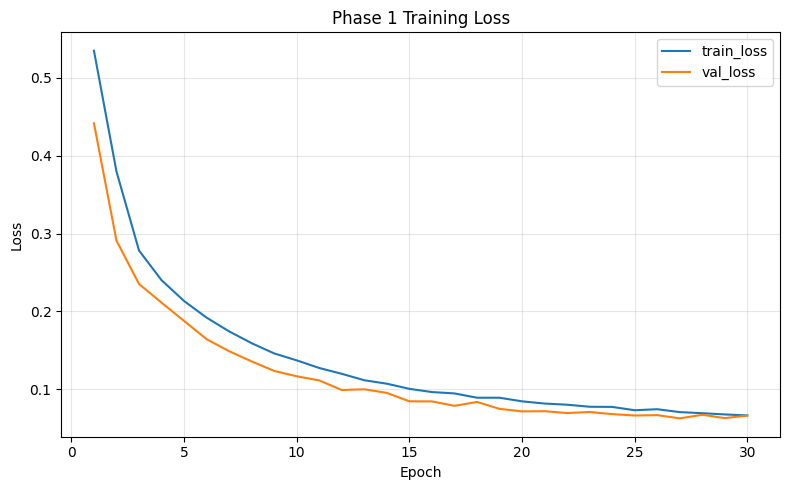

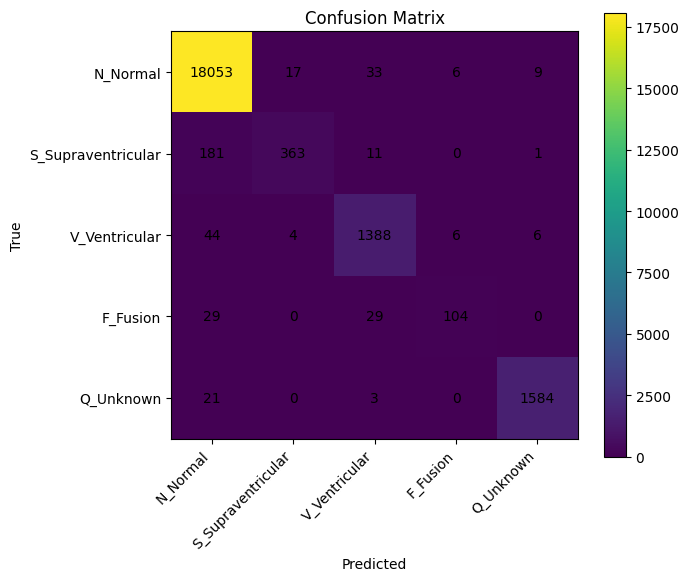

Saved figures:
- /kaggle/working/ecg_phase1_outputs/docs/figures/training_accuracy.png
- /kaggle/working/ecg_phase1_outputs/docs/figures/training_loss.png
- /kaggle/working/ecg_phase1_outputs/docs/figures/confusion_matrix.png


In [11]:
# ============================================================
# 10. Save quality figures
# ============================================================
history_df = pd.read_csv(history_path)

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_accuracy"], label="train_accuracy")
plt.plot(history_df["epoch"], history_df["val_accuracy"], label="val_accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Phase 1 Training Accuracy")
plt.grid(True, alpha=0.3)
plt.legend()
acc_fig_path = DIRS["figures"] / "training_accuracy.png"
plt.tight_layout()
plt.savefig(acc_fig_path, dpi=160)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], label="train_loss")
plt.plot(history_df["epoch"], history_df["val_loss"], label="val_loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Phase 1 Training Loss")
plt.grid(True, alpha=0.3)
plt.legend()
loss_fig_path = DIRS["figures"] / "training_loss.png"
plt.tight_layout()
plt.savefig(loss_fig_path, dpi=160)
plt.show()

plt.figure(figsize=(7, 6))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix")
plt.colorbar()
tick_marks = np.arange(CFG.num_classes)
plt.xticks(tick_marks, CFG.class_names, rotation=45, ha="right")
plt.yticks(tick_marks, CFG.class_names)
plt.xlabel("Predicted")
plt.ylabel("True")

for i in range(CFG.num_classes):
    for j in range(CFG.num_classes):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

cm_fig_path = DIRS["figures"] / "confusion_matrix.png"
plt.tight_layout()
plt.savefig(cm_fig_path, dpi=160)
plt.show()

print("Saved figures:")
print("-", acc_fig_path)
print("-", loss_fig_path)
print("-", cm_fig_path)

In [12]:
# ============================================================
# 11. Export weights and biases in FP32
# ============================================================
def tensor_stats(array: np.ndarray) -> Dict[str, object]:
    """Returns compact statistics for a NumPy array."""
    return {
        "shape": list(array.shape),
        "dtype": str(array.dtype),
        "min": float(np.min(array)) if array.size else 0.0,
        "max": float(np.max(array)) if array.size else 0.0,
        "mean": float(np.mean(array)) if array.size else 0.0,
        "std": float(np.std(array)) if array.size else 0.0,
    }


state_dict_cpu = torch.load(best_model_path, map_location="cpu")
weight_arrays: Dict[str, np.ndarray] = {}
weight_manifest: Dict[str, Dict[str, object]] = {}

for name, tensor in state_dict_cpu.items():
    array = tensor.detach().cpu().numpy().astype(np.float32)
    safe_name = name.replace(".", "__")
    npy_path = DIRS["weights"] / f"{safe_name}.npy"
    txt_path = DIRS["weights"] / f"{safe_name}.txt"

    np.save(npy_path, array)

    # Text flatten export is useful for quick inspection and later RTL memory generation.
    np.savetxt(txt_path, array.reshape(-1), fmt="%.9e")

    weight_arrays[safe_name] = array
    weight_manifest[name] = {
        **tensor_stats(array),
        "npy_path": str(npy_path),
        "txt_flat_path": str(txt_path),
        "pytorch_key": name,
        "export_key": safe_name,
    }

npz_path = DIRS["weights"] / "ecg1dcnn_weights_float32.npz"
np.savez_compressed(npz_path, **weight_arrays)

manifest_path = DIRS["weights"] / "weights_manifest.json"
with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(weight_manifest, f, indent=2)

print("Exported FP32 weights and biases.")
print("NPZ:", npz_path)
print("Manifest:", manifest_path)
display(pd.DataFrame(weight_manifest).transpose())

Exported FP32 weights and biases.
NPZ: /kaggle/working/ecg_phase1_outputs/models/weights_float32/ecg1dcnn_weights_float32.npz
Manifest: /kaggle/working/ecg_phase1_outputs/models/weights_float32/weights_manifest.json


,shape,dtype,min,max,mean,std,npy_path,txt_flat_path,pytorch_key,export_key
conv1.weight,"[16, 1, 5]",float32,-0.679106,0.62289,0.026375,0.348693,/kaggle/working/ecg_phase1_outputs/models/weig...,/kaggle/working/ecg_phase1_outputs/models/weig...,conv1.weight,conv1__weight
conv1.bias,[16],float32,-0.392524,0.233932,-0.065364,0.179008,/kaggle/working/ecg_phase1_outputs/models/weig...,/kaggle/working/ecg_phase1_outputs/models/weig...,conv1.bias,conv1__bias
conv2.weight,"[16, 16, 5]",float32,-0.787866,1.133649,-0.00166,0.169189,/kaggle/working/ecg_phase1_outputs/models/weig...,/kaggle/working/ecg_phase1_outputs/models/weig...,conv2.weight,conv2__weight
conv2.bias,[16],float32,-0.243128,0.088897,-0.041475,0.079244,/kaggle/working/ecg_phase1_outputs/models/weig...,/kaggle/working/ecg_phase1_outputs/models/weig...,conv2.bias,conv2__bias
conv3.weight,"[32, 16, 3]",float32,-0.975939,0.801899,-0.02193,0.194891,/kaggle/working/ecg_phase1_outputs/models/weig...,/kaggle/working/ecg_phase1_outputs/models/weig...,conv3.weight,conv3__weight
conv3.bias,[32],float32,-0.214124,0.200027,-0.00211,0.106125,/kaggle/working/ecg_phase1_outputs/models/weig...,/kaggle/working/ecg_phase1_outputs/models/weig...,conv3.bias,conv3__bias
conv4.weight,"[32, 32, 3]",float32,-0.779018,0.624595,-0.013265,0.158895,/kaggle/working/ecg_phase1_outputs/models/weig...,/kaggle/working/ecg_phase1_outputs/models/weig...,conv4.weight,conv4__weight
conv4.bias,[32],float32,-0.168935,0.201158,-0.001046,0.100149,/kaggle/working/ecg_phase1_outputs/models/weig...,/kaggle/working/ecg_phase1_outputs/models/weig...,conv4.bias,conv4__bias
conv5.weight,"[256, 32, 3]",float32,-1.301697,0.679905,-0.043031,0.165974,/kaggle/working/ecg_phase1_outputs/models/weig...,/kaggle/working/ecg_phase1_outputs/models/weig...,conv5.weight,conv5__weight
conv5.bias,[256],float32,-0.345289,0.402756,0.001073,0.140237,/kaggle/working/ecg_phase1_outputs/models/weig...,/kaggle/working/ecg_phase1_outputs/models/weig...,conv5.bias,conv5__bias


In [13]:
# ============================================================
# 12. Select deterministic golden samples
# ============================================================
def select_balanced_golden_indices(labels: np.ndarray, total_count: int, num_classes: int, seed: int) -> np.ndarray:
    """Selects deterministic, mostly balanced sample indices for golden export."""
    rng = np.random.default_rng(seed)
    per_class_target = max(1, total_count // num_classes)
    selected: List[int] = []

    for class_id in range(num_classes):
        class_indices = np.flatnonzero(labels == class_id)
        if len(class_indices) == 0:
            continue
        class_indices = class_indices.copy()
        rng.shuffle(class_indices)
        selected.extend(class_indices[: min(per_class_target, len(class_indices))].tolist())

    if len(selected) < total_count:
        remaining = np.setdiff1d(np.arange(len(labels)), np.array(selected, dtype=np.int64), assume_unique=False)
        rng.shuffle(remaining)
        selected.extend(remaining[: total_count - len(selected)].tolist())

    selected = selected[: min(total_count, len(labels))]
    selected = np.array(selected, dtype=np.int64)
    selected.sort()
    return selected


golden_indices = select_balanced_golden_indices(
    labels=y_test_np,
    total_count=CFG.golden_sample_count,
    num_classes=CFG.num_classes,
    seed=CFG.seed,
)

golden_x_np = X_test_np[golden_indices].astype(np.float32)
golden_y_np = y_test_np[golden_indices].astype(np.int64)

golden_index_df = pd.DataFrame(
    {
        "golden_row": np.arange(len(golden_indices)),
        "test_sample_index": golden_indices,
        "label": golden_y_np,
        "class_name": [CFG.class_names[int(v)] for v in golden_y_np],
    }
)
golden_index_df.to_csv(DIRS["golden"] / "golden_indices.csv", index=False)

print("Golden sample count:", len(golden_indices))
display(golden_index_df.head(20))
display(class_distribution(golden_y_np, "golden"))

Golden sample count: 128


,golden_row,test_sample_index,label,class_name
0,0,1638,0,N_Normal
1,1,2011,0,N_Normal
2,2,2303,0,N_Normal
3,3,2306,0,N_Normal
4,4,3652,0,N_Normal
5,5,3663,0,N_Normal
6,6,3771,0,N_Normal
7,7,3781,0,N_Normal
8,8,4296,0,N_Normal
9,9,4456,0,N_Normal


,split,class_id,class_name,count,fraction
0,golden,0,N_Normal,26,0.203125
1,golden,1,S_Supraventricular,25,0.195312
2,golden,2,V_Ventricular,26,0.203125
3,golden,3,F_Fusion,25,0.195312
4,golden,4,Q_Unknown,26,0.203125


In [14]:
# ============================================================
# 13. Export golden FP32 activations
# ============================================================
@torch.no_grad()
def collect_golden_activations(
    model: ECG1DCNN,
    golden_x: np.ndarray,
    batch_size: int = 64,
) -> Tuple[np.ndarray, Dict[str, np.ndarray]]:
    """Collects logits and intermediate activations for golden samples."""
    model.eval()

    activation_chunks: Dict[str, List[np.ndarray]] = {}
    logits_chunks: List[np.ndarray] = []

    for start in range(0, len(golden_x), batch_size):
        end = min(start + batch_size, len(golden_x))
        x_batch = torch.tensor(golden_x[start:end], dtype=torch.float32).unsqueeze(1).to(DEVICE)

        logits, activations = model.forward_with_activations(x_batch)
        logits_chunks.append(logits.detach().cpu().numpy().astype(np.float32))

        for name, tensor in activations.items():
            activation_chunks.setdefault(name, []).append(tensor.detach().cpu().numpy().astype(np.float32))

    logits_np = np.concatenate(logits_chunks, axis=0)
    activations_np = {
        name: np.concatenate(chunks, axis=0).astype(np.float32)
        for name, chunks in activation_chunks.items()
    }
    return logits_np, activations_np


model = ECG1DCNN(num_classes=CFG.num_classes, use_batch_norm=CFG.use_batch_norm).to(DEVICE)
model.load_state_dict(torch.load(best_model_path, map_location=DEVICE))
model.eval()

golden_logits_np, golden_activations = collect_golden_activations(model, golden_x_np)
golden_probs_np = softmax_np(golden_logits_np)
golden_pred_np = golden_probs_np.argmax(axis=1).astype(np.int64)

np.save(DIRS["golden"] / "golden_inputs_x_float32.npy", golden_x_np)
np.save(DIRS["golden"] / "golden_inputs_x_conv1d_float32.npy", golden_x_np[:, None, :].astype(np.float32))
np.save(DIRS["golden"] / "golden_labels_int64.npy", golden_y_np)
np.save(DIRS["golden"] / "golden_logits_float32.npy", golden_logits_np)
np.save(DIRS["golden"] / "golden_probabilities_float32.npy", golden_probs_np)
np.save(DIRS["golden"] / "golden_predictions_int64.npy", golden_pred_np)

activation_npz_path = DIRS["golden"] / "golden_activations_float32.npz"
np.savez_compressed(activation_npz_path, **golden_activations)

golden_prediction_df = pd.DataFrame(
    {
        "golden_row": np.arange(len(golden_y_np)),
        "test_sample_index": golden_indices,
        "true_label": golden_y_np,
        "pred_label": golden_pred_np,
        "correct": golden_y_np == golden_pred_np,
        **{f"logit_{i}_{CFG.class_names[i]}": golden_logits_np[:, i] for i in range(CFG.num_classes)},
        **{f"prob_{i}_{CFG.class_names[i]}": golden_probs_np[:, i] for i in range(CFG.num_classes)},
    }
)
golden_prediction_df.to_csv(DIRS["golden"] / "golden_predictions_logits_probs.csv", index=False)

activation_manifest = {
    name: {
        **tensor_stats(array),
        "description": "FP32 PyTorch activation exported in model.eval() mode",
    }
    for name, array in golden_activations.items()
}
activation_manifest["logits"] = tensor_stats(golden_logits_np)

activation_manifest_path = DIRS["golden"] / "golden_activation_manifest.json"
with open(activation_manifest_path, "w", encoding="utf-8") as f:
    json.dump(activation_manifest, f, indent=2)

golden_accuracy = accuracy_score(golden_y_np, golden_pred_np)
print("Golden export complete.")
print("Golden accuracy on selected samples:", golden_accuracy)
print("Activation NPZ:", activation_npz_path)
print("Manifest:", activation_manifest_path)
display(pd.DataFrame(activation_manifest).transpose())

Golden export complete.
Golden accuracy on selected samples: 0.828125
Activation NPZ: /kaggle/working/ecg_phase1_outputs/datasets/golden_float/golden_activations_float32.npz
Manifest: /kaggle/working/ecg_phase1_outputs/datasets/golden_float/golden_activation_manifest.json


,shape,dtype,min,max,mean,std,description
input,"[128, 1, 187]",float32,0.0,1.0,0.196809,0.243425,FP32 PyTorch activation exported in model.eval...
conv1,"[128, 16, 183]",float32,-1.097472,1.108232,-0.039122,0.198802,FP32 PyTorch activation exported in model.eval...
bn1_or_identity,"[128, 16, 183]",float32,-1.097472,1.108232,-0.039122,0.198802,FP32 PyTorch activation exported in model.eval...
relu1,"[128, 16, 183]",float32,0.0,1.108232,0.05467,0.100948,FP32 PyTorch activation exported in model.eval...
conv2,"[128, 16, 179]",float32,-1.87517,1.734761,-0.126553,0.210764,FP32 PyTorch activation exported in model.eval...
bn2_or_identity,"[128, 16, 179]",float32,-1.87517,1.734761,-0.126553,0.210764,FP32 PyTorch activation exported in model.eval...
relu2,"[128, 16, 179]",float32,0.0,1.734761,0.021719,0.0806,FP32 PyTorch activation exported in model.eval...
pool1,"[128, 16, 89]",float32,0.0,1.734761,0.026331,0.093951,FP32 PyTorch activation exported in model.eval...
drop1_eval_identity,"[128, 16, 89]",float32,0.0,1.734761,0.026331,0.093951,FP32 PyTorch activation exported in model.eval...
conv3,"[128, 32, 87]",float32,-4.202388,1.575978,-0.040574,0.221232,FP32 PyTorch activation exported in model.eval...


In [15]:
# ============================================================
# 14. Export reusable golden_model.py helper
# ============================================================
golden_model_py = '"""Phase 1 FP32 golden model for ECG 1D CNN.\n\nGenerated by the Kaggle notebook: ecg_phase1_kaggle_golden_float.ipynb\n"""\n\nfrom __future__ import annotations\n\nfrom typing import Dict, Tuple\n\nimport numpy as np\nimport torch\nimport torch.nn as nn\n\n\nclass ECG1DCNN(nn.Module):\n    """1D CNN FP32 golden reference model."""\n\n    def __init__(self, num_classes: int = 5, use_batch_norm: bool = False):\n        super().__init__()\n        self.conv1 = nn.Conv1d(1, 16, kernel_size=5)\n        self.bn1 = nn.BatchNorm1d(16) if use_batch_norm else nn.Identity()\n        self.relu1 = nn.ReLU()\n\n        self.conv2 = nn.Conv1d(16, 16, kernel_size=5)\n        self.bn2 = nn.BatchNorm1d(16) if use_batch_norm else nn.Identity()\n        self.relu2 = nn.ReLU()\n\n        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)\n        self.drop1 = nn.Dropout(0.1)\n\n        self.conv3 = nn.Conv1d(16, 32, kernel_size=3)\n        self.bn3 = nn.BatchNorm1d(32) if use_batch_norm else nn.Identity()\n        self.relu3 = nn.ReLU()\n\n        self.conv4 = nn.Conv1d(32, 32, kernel_size=3)\n        self.bn4 = nn.BatchNorm1d(32) if use_batch_norm else nn.Identity()\n        self.relu4 = nn.ReLU()\n\n        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)\n        self.drop2 = nn.Dropout(0.1)\n\n        self.conv5 = nn.Conv1d(32, 256, kernel_size=3)\n        self.bn5 = nn.BatchNorm1d(256) if use_batch_norm else nn.Identity()\n        self.relu5 = nn.ReLU()\n\n        self.conv6 = nn.Conv1d(256, 256, kernel_size=3)\n        self.bn6 = nn.BatchNorm1d(256) if use_batch_norm else nn.Identity()\n        self.relu6 = nn.ReLU()\n\n        self.global_max_pool = nn.AdaptiveMaxPool1d(1)\n        self.drop3 = nn.Dropout(0.2)\n\n        self.fc1 = nn.Linear(256, 64)\n        self.relu7 = nn.ReLU()\n\n        self.fc2 = nn.Linear(64, 64)\n        self.relu8 = nn.ReLU()\n\n        self.fc3 = nn.Linear(64, num_classes)\n\n    def forward_with_activations(self, x: torch.Tensor) -> Tuple[torch.Tensor, Dict[str, torch.Tensor]]:\n        activations: Dict[str, torch.Tensor] = {"input": x}\n\n        x = self.conv1(x); activations["conv1"] = x\n        x = self.bn1(x); activations["bn1_or_identity"] = x\n        x = self.relu1(x); activations["relu1"] = x\n\n        x = self.conv2(x); activations["conv2"] = x\n        x = self.bn2(x); activations["bn2_or_identity"] = x\n        x = self.relu2(x); activations["relu2"] = x\n\n        x = self.pool1(x); activations["pool1"] = x\n        x = self.drop1(x); activations["drop1_eval_identity"] = x\n\n        x = self.conv3(x); activations["conv3"] = x\n        x = self.bn3(x); activations["bn3_or_identity"] = x\n        x = self.relu3(x); activations["relu3"] = x\n\n        x = self.conv4(x); activations["conv4"] = x\n        x = self.bn4(x); activations["bn4_or_identity"] = x\n        x = self.relu4(x); activations["relu4"] = x\n\n        x = self.pool2(x); activations["pool2"] = x\n        x = self.drop2(x); activations["drop2_eval_identity"] = x\n\n        x = self.conv5(x); activations["conv5"] = x\n        x = self.bn5(x); activations["bn5_or_identity"] = x\n        x = self.relu5(x); activations["relu5"] = x\n\n        x = self.conv6(x); activations["conv6"] = x\n        x = self.bn6(x); activations["bn6_or_identity"] = x\n        x = self.relu6(x); activations["relu6"] = x\n\n        x = self.global_max_pool(x); activations["global_max_pool"] = x\n        x = self.drop3(x); activations["drop3_eval_identity"] = x\n\n        x = torch.flatten(x, 1); activations["flatten"] = x\n\n        x = self.fc1(x); activations["fc1"] = x\n        x = self.relu7(x); activations["relu7"] = x\n\n        x = self.fc2(x); activations["fc2"] = x\n        x = self.relu8(x); activations["relu8"] = x\n\n        logits = self.fc3(x); activations["logits"] = logits\n        return logits, activations\n\n    def forward(self, x: torch.Tensor) -> torch.Tensor:\n        logits, _ = self.forward_with_activations(x)\n        return logits\n\n\ndef load_model(weights_path: str, device: str = "cpu", use_batch_norm: bool = False) -> ECG1DCNN:\n    """Loads the ECG1DCNN model from a PyTorch state_dict file."""\n    model = ECG1DCNN(num_classes=5, use_batch_norm=use_batch_norm).to(device)\n    state_dict = torch.load(weights_path, map_location=device)\n    model.load_state_dict(state_dict)\n    model.eval()\n    return model\n\n\n@torch.no_grad()\ndef run_golden_inference(\n    model: ECG1DCNN,\n    x_np: np.ndarray,\n    device: str = "cpu",\n) -> Tuple[np.ndarray, Dict[str, np.ndarray]]:\n    """Runs FP32 inference and returns logits plus intermediate activations."""\n    if x_np.ndim == 2:\n        x_np = x_np[:, None, :]\n    x = torch.tensor(x_np, dtype=torch.float32, device=device)\n    logits, activations = model.forward_with_activations(x)\n    logits_np = logits.detach().cpu().numpy().astype(np.float32)\n    activations_np = {\n        name: tensor.detach().cpu().numpy().astype(np.float32)\n        for name, tensor in activations.items()\n    }\n    return logits_np, activations_np\n'

golden_model_path = DIRS["src"] / "golden_model.py"
golden_model_path.write_text(golden_model_py.strip() + "\n", encoding="utf-8")
print("Wrote:", golden_model_path)

Wrote: /kaggle/working/ecg_phase1_outputs/models/float/golden_model.py


In [16]:
# ============================================================
# 15. Phase 1 smoke checks
# ============================================================
smoke_results = {}

# Dataset checks.
smoke_results["dataset_train_shape_ok"] = X_train_np.shape[1] == CFG.input_length
smoke_results["dataset_test_shape_ok"] = X_test_np.shape[1] == CFG.input_length

# Model checks.
smoke_results["param_count_ok"] = (param_count == 248_693) if not CFG.use_batch_norm else True
smoke_results["best_model_exists"] = best_model_path.exists()
smoke_results["weights_manifest_exists"] = manifest_path.exists()
smoke_results["golden_activations_exists"] = activation_npz_path.exists()

# Forward pass shape check.
with torch.no_grad():
    sample_x = torch.tensor(X_test_np[:4], dtype=torch.float32).unsqueeze(1).to(DEVICE)
    sample_logits, sample_acts = model.forward_with_activations(sample_x)

smoke_results["forward_logits_shape_ok"] = list(sample_logits.shape) == [4, CFG.num_classes]
smoke_results["pool1_shape_ok"] = list(sample_acts["pool1"].shape[1:]) == [16, 89]
smoke_results["pool2_shape_ok"] = list(sample_acts["pool2"].shape[1:]) == [32, 42]
smoke_results["global_max_pool_shape_ok"] = list(sample_acts["global_max_pool"].shape[1:]) == [256, 1]

smoke_results["all_passed"] = all(bool(v) for v in smoke_results.values())

smoke_path = OUTPUT_ROOT / "phase1_smoke_test_result.json"
with open(smoke_path, "w", encoding="utf-8") as f:
    json.dump(smoke_results, f, indent=2)

print(json.dumps(smoke_results, indent=2))
if not smoke_results["all_passed"]:
    raise RuntimeError("Phase 1 smoke test failed. Inspect phase1_smoke_test_result.json.")
print("Smoke test passed:", smoke_path)

{
  "dataset_train_shape_ok": true,
  "dataset_test_shape_ok": true,
  "param_count_ok": true,
  "best_model_exists": true,
  "weights_manifest_exists": true,
  "golden_activations_exists": true,
  "forward_logits_shape_ok": true,
  "pool1_shape_ok": true,
  "pool2_shape_ok": true,
  "global_max_pool_shape_ok": true,
  "all_passed": true
}
Smoke test passed: /kaggle/working/ecg_phase1_outputs/phase1_smoke_test_result.json


In [17]:
# ============================================================
# 16. Generate Phase 1 markdown reports
# ============================================================
def write_text(path: Path, content: str) -> None:
    """Writes UTF-8 text and creates parent directories."""
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(content.strip() + "\n", encoding="utf-8")


requirements_contract = f"""
# Requirements Contract v01 — ECG 1D CNN Phase 1

## Objective

Build a floating-point PyTorch golden reference for ECG heartbeat classification before fixed-point and RTL work.

## Dataset Contract

- Dataset: MIT-BIH Arrhythmia heartbeat CSV files.
- Train CSV: `{TRAIN_CSV}`
- Test CSV: `{TEST_CSV}`
- Feature columns: `0..186`
- Label column: `187`
- Input tensor shape for PyTorch Conv1d: `(batch, 1, 187)`
- Number of classes: `{CFG.num_classes}`
- Classes: `{', '.join(CFG.class_names)}`

## Model Contract

- Model: `ECG1DCNN`
- Padding: valid/no padding.
- BatchNorm: `{CFG.use_batch_norm}`
- Dropout: training only; disabled during `model.eval()`.
- Trainable parameters: `{param_count:,}`
- Output: raw logits with shape `(batch, 5)`.

## Phase 1 Acceptance

- Dataset shape validated.
- PyTorch model trained and checkpointed.
- Test baseline generated.
- FP32 weights and biases exported.
- FP32 golden inputs, labels, logits, probabilities, predictions, and activations exported.
- Smoke test passed: `{smoke_results["all_passed"]}`.
"""

environment_report = f"""
# Phase 1.2 Environment and Dataset Report

## Environment

```json
{json.dumps(ENV_INFO, indent=2)}
```

## Dataset

- Data directory: `{DATA_DIR}`
- Train split shape: `{X_train_np.shape}`
- Validation split shape: `{X_val_np.shape}`
- Test split shape: `{X_test_np.shape}`
- Data contract: `{OUTPUT_ROOT / "data_contract.json"}`
- Class distribution CSV: `{OUTPUT_ROOT / "dataset_class_distribution.csv"}`

## Command

Run this Kaggle notebook top-to-bottom.

## Expected Outputs

- `{OUTPUT_ROOT / "data_contract.json"}`
- `{OUTPUT_ROOT / "dataset_class_distribution.csv"}`
- `{OUTPUT_ROOT / "requirements.txt"}`

## Known Issues

- Kaggle dataset path may vary. The notebook searches common paths and recursively scans `/kaggle/input`.
- If the dataset is not attached to the Kaggle notebook, Cell 2 will raise `FileNotFoundError`.
"""

golden_model_report = f"""
# Phase 1.3 Golden Model Report

## Objective

Create a bit-accurate FP32 PyTorch golden reference for the ECG 1D CNN.

## Model

- Checkpoint: `{best_model_path}`
- Reusable model file: `{golden_model_path}`
- Architecture trace: `{OUTPUT_ROOT / "model_shape_trace.csv"}`
- Architecture contract JSON: `{DIRS["architecture"] / "model_architecture_contract_v01.json"}`
- Parameter count: `{param_count:,}`

## Weight Export

- Combined NPZ: `{npz_path}`
- Manifest: `{manifest_path}`
- Individual `.npy` and flattened `.txt` files: `{DIRS["weights"]}`

## Golden Float Export

- Golden sample count: `{len(golden_indices)}`
- Golden sample index CSV: `{DIRS["golden"] / "golden_indices.csv"}`
- Inputs: `{DIRS["golden"] / "golden_inputs_x_float32.npy"}`
- Conv1d inputs: `{DIRS["golden"] / "golden_inputs_x_conv1d_float32.npy"}`
- Labels: `{DIRS["golden"] / "golden_labels_int64.npy"}`
- Logits: `{DIRS["golden"] / "golden_logits_float32.npy"}`
- Probabilities: `{DIRS["golden"] / "golden_probabilities_float32.npy"}`
- Predictions: `{DIRS["golden"] / "golden_predictions_int64.npy"}`
- Activations NPZ: `{activation_npz_path}`
- Activation manifest: `{activation_manifest_path}`

## Smoke Test

Smoke test passed: `{smoke_results["all_passed"]}`

## Notes for Phase 2

Use the exported activations and weights as the baseline when building the hardware-shaped and fixed-point models.
"""

quality_report = f"""
# Phase 1.4 Quality Baseline Report

## Objective

Record the floating-point quality baseline before quantization and RTL implementation.

## Test Metrics

```json
{json.dumps(metrics, indent=2)}
```

## Classification Report

```text
{report_text}
```

## Artifacts

- Metrics JSON: `{OUTPUT_ROOT / "quality_metrics.json"}`
- Classification report CSV: `{OUTPUT_ROOT / "classification_report.csv"}`
- Confusion matrix CSV: `{OUTPUT_ROOT / "confusion_matrix.csv"}`
- Test predictions CSV: `{OUTPUT_ROOT / "test_predictions_logits_probs.csv"}`
- Training history CSV: `{history_path}`
- Accuracy figure: `{acc_fig_path}`
- Loss figure: `{loss_fig_path}`
- Confusion matrix figure: `{cm_fig_path}`

## Result Summary

- Test accuracy: `{test_accuracy:.6f}`
- Test macro F1: `{test_macro_f1:.6f}`
- Average inference latency per sample on current runtime: `{metrics["average_inference_ms_per_sample"]:.6f} ms/sample`

## Next Actions

- Phase 2: build hardware-shaped Python model using the exact layer order and exported FP32 artifacts.
- Phase 2: quantize weights/activations and compare fixed-point outputs against this FP32 golden reference.
"""

readme = f"""
# ECG Phase 1 Kaggle Outputs

This folder was generated by `ecg_phase1_kaggle_golden_float.ipynb`.

## Main Artifacts

- Best PyTorch model: `models/best_ecg1dcnn_float32.pth`
- Full checkpoint: `models/phase1_checkpoint.pth`
- Golden model helper: `models/float/golden_model.py`
- FP32 weights: `models/weights_float32/`
- Golden FP32 vectors: `datasets/golden_float/`
- Reports: `docs/reports/`
- Architecture contract: `docs/architecture/model_architecture_contract_v01.json`
- Quality metrics: `quality_metrics.json`

## How to Reproduce

Run all notebook cells top-to-bottom on Kaggle with the MIT-BIH heartbeat dataset attached.

## Phase 1 Status

Smoke test passed: `{smoke_results["all_passed"]}`
"""

write_text(DIRS["architecture"] / "requirements_contract_v01.md", requirements_contract)
write_text(DIRS["reports"] / "phase1_2_environment_dataset_report.md", environment_report)
write_text(DIRS["reports"] / "phase1_3_golden_model_report.md", golden_model_report)
write_text(DIRS["reports"] / "phase1_4_quality_baseline_report.md", quality_report)
write_text(OUTPUT_ROOT / "README.md", readme)

report_paths = [
    DIRS["architecture"] / "requirements_contract_v01.md",
    DIRS["reports"] / "phase1_2_environment_dataset_report.md",
    DIRS["reports"] / "phase1_3_golden_model_report.md",
    DIRS["reports"] / "phase1_4_quality_baseline_report.md",
    OUTPUT_ROOT / "README.md",
]
print("Generated reports:")
for path in report_paths:
    print("-", path)

Generated reports:
- /kaggle/working/ecg_phase1_outputs/docs/architecture/requirements_contract_v01.md
- /kaggle/working/ecg_phase1_outputs/docs/reports/phase1_2_environment_dataset_report.md
- /kaggle/working/ecg_phase1_outputs/docs/reports/phase1_3_golden_model_report.md
- /kaggle/working/ecg_phase1_outputs/docs/reports/phase1_4_quality_baseline_report.md
- /kaggle/working/ecg_phase1_outputs/README.md


In [18]:
# ============================================================
# 17. Package Phase 1 artifacts into a ZIP file
# ============================================================
zip_path = OUTPUT_ROOT.parent / "ecg_phase1_artifacts.zip"

if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for file_path in OUTPUT_ROOT.rglob("*"):
        if file_path.is_file():
            zf.write(file_path, arcname=file_path.relative_to(OUTPUT_ROOT.parent))

artifact_index_rows = []
for file_path in sorted(OUTPUT_ROOT.rglob("*")):
    if file_path.is_file():
        artifact_index_rows.append(
            {
                "path": str(file_path.relative_to(OUTPUT_ROOT)),
                "size_bytes": file_path.stat().st_size,
            }
        )

artifact_index_df = pd.DataFrame(artifact_index_rows)
artifact_index_df.to_csv(OUTPUT_ROOT / "artifact_index.csv", index=False)

print("Phase 1 artifact ZIP:", zip_path)
print("Artifact count:", len(artifact_index_rows))
display(artifact_index_df.head(50))

print("\nDONE: Phase 1 notebook completed successfully.")

Phase 1 artifact ZIP: /kaggle/working/ecg_phase1_artifacts.zip
Artifact count: 71


,path,size_bytes
0,README.md,681
1,classification_report.csv,629
2,confusion_matrix.csv,196
3,data_contract.json,2201
4,dataset_class_distribution.csv,698
5,datasets/golden_float/golden_activation_manife...,8881
6,datasets/golden_float/golden_activations_float...,23573167
7,datasets/golden_float/golden_indices.csv,3016
8,datasets/golden_float/golden_inputs_x_conv1d_f...,95872
9,datasets/golden_float/golden_inputs_x_float32.npy,95872



DONE: Phase 1 notebook completed successfully.
